**รายชื่อสมาชิก รหัสนักศึกษา และหน้าที่รับผิดชอบ**

| ชื่อ–สกุล | รหัสนักศึกษา | หน้าที่ |
|---|---|---|
| สิริภัท ธนสุขโสภณ | 6809540179 | ยังไม่กำหนด |
| ภณวรรชน์ โขงเขตต์ | 6809617282 | ยังไม่กำหนด |
| รมณ ประภาพรสุข | 6809617332 | ยังไม่กำหนด |
| วิรมณ มาเกิด | 6809617407 | ยังไม่กำหนด |
| อานัส บินเสะ | 6809617522 | ยังไม่กำหนด |
| ณพวุฒิ วิทยากุล | 6809681429 | ยังไม่กำหนด |
| ปาณิศรา แวงดิศร | 6809681452 | ยังไม่กำหนด |
| ศรัณย์วิชญ์ โพธิ์ชัย | 6809681478 | ยังไม่กำหนด |
| อานนท์ พูนสิน | 6809681494 | ยังไม่กำหนด |


# พยากรณ์จำนวนอุบัติเหตุเดือนหน้า

**ปัญหา:** การจัดกำลังตรวจตราล่วงหน้าทำได้ยาก หากยังไม่ทราบว่าสายทางใดอาจมีเหตุจำนวนมากในเดือนหน้า

**เป้าหมาย:** พยากรณ์จำนวนอุบัติเหตุที่บันทึกในเดือนถัดไปบน 4 สายทางในกรุงเทพฯ เพื่อช่วยวางแผนเฝ้าระวัง งานนี้ใช้ **Regression** เพราะผลทำนายเป็นจำนวนเหตุ

อ่านข้อมูล → เตรียมและสำรวจข้อมูล → เปรียบเทียบ 3 โมเดล → พยากรณ์เดือนถัดไป

## 1. แหล่งข้อมูล (Data Collection)

ใช้ไฟล์ CSV อุบัติเหตุทางถนนจาก [กระทรวงคมนาคม / TRAMS](https://datagov.mot.go.th/dataset/roadaccident) ปี 2564–2569 โดยปี 2569 มีข้อมูลถึงเดือนตุลาคม ไฟล์ในโฟลเดอร์ `data/` คัดเฉพาะรายการในกรุงเทพฯ ไว้แล้ว

ข้อมูลอยู่ในรูปตาราง หนึ่งแถวคือหนึ่งรายการที่บันทึก **ข้อมูลเชิงคุณภาพ** เช่น หน่วยงานและรหัสสายทาง เมื่อรวมเป็นรายเดือนจะได้ **ข้อมูลเชิงปริมาณ** คือจำนวนเหตุที่บันทึกต่อสายทางต่อเดือน

In [9]:
# เซลล์นี้นำเข้าเครื่องมือสำหรับจัดการข้อมูล วาดกราฟ และฝึกโมเดล
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

In [10]:
# ย้อนจาก notebooks/ ไปอ่านข้อมูลใน data/
data_dir = Path("../data")

years = [2021, 2022, 2023, 2024, 2025, 2026]

In [11]:
# เซลล์นี้อ่านไฟล์ทีละปี ลบแถวซ้ำ และรวมเป็นตารางเดียว
frames = []

for year in years:
    table = pd.read_csv(
        data_dir / f"accident{year}.csv",
        dtype=str,
        encoding="utf-8-sig"
    )
    table = table.drop_duplicates()
    table["year"] = year
    frames.append(table)

data = pd.concat(frames, ignore_index=True)

In [12]:
# เซลล์นี้เปลี่ยนชื่อและเลือกคอลัมน์ที่ใช้
data = data.rename(columns={
    "วันที่เกิดเหตุ": "date",
    "เวลา": "time",
    "หน่วยงาน": "agency",
    "รหัสสายทาง": "route_code"
})

data = data[["year", "date", "time", "agency", "route_code", "ACC_CODE"]]

In [13]:
# เซลล์นี้แสดงข้อมูลตัวอย่างและขนาดตาราง
print(data.head())
print("แสดงจำนวนแถวและจำนวนคอลัมน์", data.shape)

   year      date   time      agency route_code ACC_CODE
0  2021  1/1/2021   2:00  กรมทางหลวง        338  3813107
1  2021  1/1/2021  11:00  กรมทางหลวง          9  3805748
2  2021  1/1/2021  19:00  กรมทางหลวง        304  5746608
3  2021  1/3/2021  10:28  กรมทางหลวง          7  3805955
4  2021  1/3/2021  10:30  กรมทางหลวง        304  4607166
แสดงจำนวนแถวและจำนวนคอลัมน์ (13569, 6)


## 2. เตรียมข้อมูล (Data Preparation)

แปลงวันที่ให้ตรงกัน ตรวจหน่วยงานและรหัสสายทาง แล้วจัดการรายการซ้ำ หากรหัสเหตุเดียวกันในปีเดียวกันมีวันที่ เวลา หรือสายทางขัดแย้งกัน จะตัดทั้งกลุ่มออก

In [14]:
# เก็บวันที่เดิม และเตรียมช่องสำหรับวันที่ที่แปลงแล้ว
data["date_text"] = data["date"]
data["date"] = pd.NaT

# ปี 2021–2023 บันทึกเป็น เดือน/วัน/ปี
rows = data["year"].isin([2021, 2022, 2023])
data.loc[rows, "date"] = pd.to_datetime(
    data.loc[rows, "date_text"], format="%m/%d/%Y", errors="coerce"
)

In [15]:
# เซลล์นี้แปลงวันที่ของปี 2567–2568 จากตัวเลขวันที่ของ Excel
rows = data["year"].isin([2024, 2025])

numbers = pd.to_numeric(data.loc[rows, "date_text"], errors="coerce")

data.loc[rows, "date"] = pd.to_datetime(
    numbers, unit="D", origin="1899-12-30", errors="coerce"
)

In [16]:
# ปี 2026 บันทึกเป็น วัน/เดือน/ปี
rows = data["year"].eq(2026)
data.loc[rows, "date"] = pd.to_datetime(
    data.loc[rows, "date_text"], format="%d/%m/%Y", errors="coerce"
)

In [17]:
# ลบแถวที่ไม่มีวันที่ หน่วยงาน หรือรหัสสายทาง
data = data.dropna(subset=["date", "agency", "route_code"])

# เก็บเฉพาะวันที่ที่ปีตรงกับปีของไฟล์
data = data[data["date"].dt.year == data["year"]].copy()

# ลบช่องว่างหัวท้าย
data["agency"] = data["agency"].str.strip()
data["route_code"] = data["route_code"].str.strip()

# รวมหน่วยงานกับรหัสสายทาง เช่น กรมทางหลวง:9
data["route_id"] = data["agency"] + ":" + data["route_code"]

### 38 คอลัมน์ / 61 รหัส / 4 สายทาง ต่างกันอย่างไร?
- **38 คอลัมน์:** ประเภทข้อมูลใน CSV ต้นฉบับ เช่น วันที่ จังหวัด รหัสสายทาง
- **61 รหัสสายทาง:** รหัสที่พบในข้อมูลกรุงเทพฯ รวมปี 2564–2569 โดยนับคู่กับหน่วยงาน ไม่ใช่ถนนทั้งหมดในกรุงเทพฯ
- **4 สายทาง:** ที่เลือกมาทดลอง ได้แก่ 9 กาญจนาภิเษก, 7 มอเตอร์เวย์, 338 บรมราชชนนี และ 35 พระราม 2

Input ของสายทางคือ `route_id` เช่น `กรมทางหลวง:9` ใช้หน่วยงานร่วมด้วยเพื่อไม่ให้รหัสเลขเดียวกันของคนละหน่วยงานสับสน

In [18]:
# นับก่อนเลือก 4 สายทาง เพื่อให้เห็นขอบเขตข้อมูลจริง
all_route_count = data["route_id"].nunique()
print("รหัสสายทางทั้งหมดที่พบในข้อมูลกรุงเทพฯ:", all_route_count)

รหัสสายทางทั้งหมดที่พบในข้อมูลกรุงเทพฯ: 61


In [19]:
# เลือกเฉพาะรายการที่มีรหัสอุบัติเหตุ
known = data.dropna(subset=["ACC_CODE"])

rows_to_remove = []

# ตรวจรายการที่มีปีและรหัสอุบัติเหตุเดียวกัน
for accident_id, group in known.groupby(["year", "ACC_CODE"]):
    details = group[["date", "time", "route_id"]].drop_duplicates()

    # ถ้ามีรายละเอียดมากกว่า 1 แบบ ถือว่าข้อมูลขัดแย้ง
    if len(details) > 1:
        rows_to_remove.extend(group.index)

print("จำนวนแถวที่ข้อมูลขัดแย้ง:", len(rows_to_remove))

# ตัดแถวที่ขัดแย้งออก
data = data.drop(index=rows_to_remove)

จำนวนแถวที่ข้อมูลขัดแย้ง: 166


In [20]:
# เก็บจำนวนก่อนลบรายการซ้ำ
before = len(data)

# ตรวจรายการซ้ำเฉพาะแถวที่มีรหัสอุบัติเหตุ
known = data.dropna(subset=["ACC_CODE"])
duplicate_rows = known[
    known.duplicated(subset=["year", "ACC_CODE"])
].index

# ลบรายการซ้ำ
data = data.drop(index=duplicate_rows).copy()

print("ก่อนลบรายการซ้ำ:", before)
print("หลังลบรายการซ้ำ:", len(data))
print("ลบออก:", before - len(data), "แถว")

ก่อนลบรายการซ้ำ: 13401
หลังลบรายการซ้ำ: 13247
ลบออก: 154 แถว


### รวมและสำรวจข้อมูลรายเดือน (EDA)

เลือก 4 สายทางที่มีรายการมากที่สุดในช่วงปี 2564–2566 จากนั้นนับจำนวนเหตุรายเดือนของสายทางเหล่านี้ตลอดช่วงข้อมูล เดือนที่ไม่พบรายการในไฟล์ใช้ค่า 0

In [21]:
# ใช้ข้อมูลถึงปี 2023 เพื่อเลือกสายทาง
past = data[data["year"] <= 2023]

# เลือก 4 สายทางที่มีจำนวนรายการมากที่สุด
routes = past["route_id"].value_counts().head(4).index.tolist()

# เก็บเฉพาะข้อมูลของ 4 สายทางนี้จากทุกปี
data = data[data["route_id"].isin(routes)].copy()

# เปลี่ยนวันที่เป็นปี-เดือน เช่น 2023-01
data["month"] = data["date"].dt.to_period("M")

In [22]:
# สร้างตารางให้ครบทุกสายทางและทุกเดือน
# กำหนดช่วงเดือนที่ใช้
months = pd.period_range("2021-01", "2026-10", freq="M")

# เตรียมช่องให้ครบทุกสายทางและทุกเดือน
index = pd.MultiIndex.from_product(
    [routes, months],
    names=["route_id", "month"]
)

# นับจำนวนรายการในแต่ละสายทางและเดือน
counts = data.groupby(["route_id", "month"]).size()

# เดือนที่ไม่มีรายการให้เป็น 0 และตั้งชื่อจำนวนเหตุว่า count
monthly = counts.reindex(index, fill_value=0)
monthly = monthly.rename("count").reset_index()

# ดูตัวอย่าง
monthly.head()

,route_id,month,count
0,กรมทางหลวง:9,2021-01,23
1,กรมทางหลวง:9,2021-02,35
2,กรมทางหลวง:9,2021-03,30
3,กรมทางหลวง:9,2021-04,56
4,กรมทางหลวง:9,2021-05,33


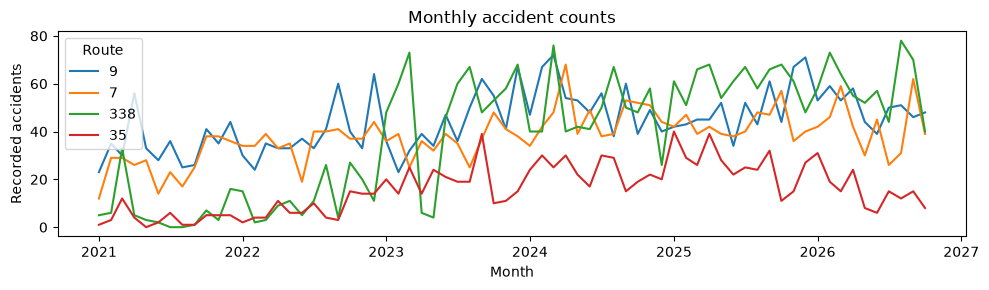

In [23]:
# ดูภาพรวมจำนวนเหตุย้อนหลัง
# สร้างพื้นที่วาดกราฟ กว้าง 10 นิ้ว สูง 3 นิ้ว
fig, ax = plt.subplots(figsize=(10, 3))

# วาดเส้นกราฟทีละสายทาง
for route in routes:
    # เลือกข้อมูลของสายทางนี้
    rows = monthly[monthly["route_id"] == route]

    ax.plot(
        rows["month"].dt.to_timestamp(),  # แกนนอน: แปลงเดือนเป็นวันที่สำหรับวาดกราฟ
        rows["count"],                   # แกนตั้ง: จำนวนอุบัติเหตุ
        label=route.split(":")[-1]        # ชื่อเส้น: ใช้เฉพาะรหัสสายทาง
    )

# ตั้งชื่อแกนและชื่อกราฟ
ax.set_xlabel("Month")
ax.set_ylabel("Recorded accidents")
ax.set_title("Monthly accident counts")

# แสดงคำอธิบายว่าแต่ละเส้นเป็นสายทางใด
ax.legend(title="Route")

# จัดระยะให้ข้อความพอดี แล้วแสดงกราฟ
plt.tight_layout()
plt.show()

### ข้อค้นพบจากข้อมูล (EDA Insights)

- ใน 4 สายทางที่ศึกษา สายทาง 9 มีจำนวนเหตุที่บันทึกเฉลี่ยสูงสุดที่ **44.6 เหตุต่อเดือน** ส่วนสายทาง 35 เฉลี่ยประมาณ **16 เหตุต่อเดือน**
- จำนวนเหตุเปลี่ยนได้มากในแต่ละเดือน เช่น สายทาง 9 มีตั้งแต่ **23 ถึง 72 เหตุต่อเดือน** ในช่วงข้อมูลที่ศึกษา

ข้อมูลไม่มีปริมาณจราจร จึงคำนวณความเสี่ยงต่อรถหนึ่งคันจากจำนวนเหตุนี้ไม่ได้

### ข้อมูลที่ใช้ทำนาย

| Feature | ใช้ข้อมูลอะไร |
|---|---|
| `lag1`, `lag2`, `lag3` | จำนวนเหตุของสายทางนั้นย้อนหลัง 1, 2 และ 3 เดือน |
| `mean3` | จำนวนเหตุเฉลี่ย 3 เดือนก่อนหน้า |
| `month_number` | หมายเลขเดือนที่จะทำนาย |
| `route_id` | รหัสสายทางที่จะทำนาย เช่น `กรมทางหลวง:9` |

**ตัวอย่าง:** ถ้าจะทำนายเดือนพฤศจิกายน และเดือนตุลาคม กันยายน สิงหาคม มี 30, 40, 50 เหตุตามลำดับ จะได้ `lag1 = 30`, `lag2 = 40`, `lag3 = 50` และ `mean3 = 40`

**Target (`count`)** คือจำนวนเหตุจริงที่บันทึกในเดือนที่ทำนาย

Features มี 6 ตัว แบ่งเป็นตัวเลข 4 ตัวและหมวดหมู่ 2 ตัว โดย `route_id` หนึ่งคอลัมน์เก็บรหัสของทั้ง 4 สายทาง

In [24]:
# เซลล์นี้สร้างฟังก์ชันสำหรับเพิ่มข้อมูลย้อนหลังที่จะใช้ทำนาย
def add_features(table):
    # เรียงข้อมูลตามสายทางและเดือน เพื่อให้ลำดับเวลาถูกต้อง
    table = table.sort_values(["route_id", "month"]).copy()

    # ดึงจำนวนเหตุย้อนหลัง 1, 2 และ 3 เดือน แยกตามสายทาง
    for lag in [1, 2, 3]:
        table[f"lag{lag}"] = table.groupby("route_id")["count"].shift(lag)

    # คำนวณจำนวนเหตุเฉลี่ยของ 3 เดือนก่อนหน้า
    table["mean3"] = (table["lag1"] + table["lag2"] + table["lag3"]) / 3

    # ดึงหมายเลขเดือน และเก็บเป็นข้อความเพื่อใช้เป็นหมวดหมู่
    table["month_number"] = table["month"].dt.month.astype(str)

    # ส่งตารางที่เพิ่มคอลัมน์แล้วกลับไป
    return table

In [25]:
# เซลล์นี้เตรียม features และเลือกข้อมูลที่มีประวัติย้อนหลังครบ 3 เดือน
# Features ที่เป็นตัวเลข
numeric = ["lag1", "lag2", "lag3", "mean3"]

# Features ที่เป็นหมวดหมู่
categorical = ["month_number", "route_id"]

# รวมรายชื่อ features ทั้ง 6 ตัว
features = numeric + categorical

# เพิ่มคอลัมน์ข้อมูลย้อนหลัง
prepared = add_features(monthly)

# ตัดแถวที่ยังมีข้อมูลย้อนหลังไม่ครบ
prepared = prepared.dropna(subset=numeric).copy()

# แสดงตัวอย่างข้อมูลที่เตรียมแล้ว
prepared[["month", "route_id", "count"] + features[:-1]].head(3)

,month,route_id,count,lag1,lag2,lag3,mean3,month_number
143,2021-04,กรมทางหลวง:338,5,33.0,6.0,5.0,14.666667,4
144,2021-05,กรมทางหลวง:338,3,5.0,33.0,6.0,14.666667,5
145,2021-06,กรมทางหลวง:338,2,3.0,5.0,33.0,13.666667,6


## 3. แบ่งข้อมูลตามเวลา

| ชุดข้อมูล | ช่วงเวลา | ใช้ทำอะไร |
|---|---|---|
| Train | เม.ย. 2564–ธ.ค. 2566 | ฝึกโมเดลครั้งแรก |
| Validation | ม.ค.–ธ.ค. 2567 | เปรียบเทียบและเลือกจาก 3 โมเดล |
| Test | ม.ค. 2568–ต.ค. 2569 | วัดความคลาดเคลื่อนในช่วงถัดไป |

เมื่อฝึกใหม่รายเดือน ให้ใช้ข้อมูลถึงเดือนก่อนหน้าเท่านั้น เช่น ทำนายมีนาคมด้วยข้อมูลถึงกุมภาพันธ์ เมื่อรู้ค่าจริงของมีนาคมแล้วจึงนำไปฝึกสำหรับเดือนเมษายน

In [26]:
# ชุดฝึก: ก่อนปี 2024
train = prepared[
    prepared["month"] < pd.Period("2024-01")
].copy()

# ชุดเลือกโมเดล: ปี 2024
validation = prepared[
    prepared["month"].dt.year == 2024
].copy()

# ชุดทดสอบ: ตั้งแต่ปี 2025 เป็นต้นไป
test = prepared[
    prepared["month"] >= pd.Period("2025-01")
].copy()

# แสดงจำนวนแถวของแต่ละชุด
print("Train:", len(train), "แถว")
print("Validation:", len(validation), "แถว")
print("Test:", len(test), "แถว")

Train: 132 แถว
Validation: 48 แถว
Test: 88 แถว


### สร้างข้อมูลไม่สมบูรณ์ตามโจทย์อาจารย์
ทำบนสำเนา Train: สร้างค่าว่าง ค่าติดลบ และแถวซ้ำ แล้วแก้ไข
ไม่เปลี่ยน `count` ซึ่งเป็นคำตอบ และไม่ทำให้ Validation/Test เสีย

In [27]:
# คัดลอกข้อมูล เพื่อเก็บ Train เดิมไว้
train_dirty = train.copy()

# กำหนดให้การสุ่มได้ผลเหมือนเดิมทุกครั้ง
rng = np.random.default_rng(42)

# สุ่ม 5 แถว แล้วทำให้จำนวนเหตุเดือนก่อนหน้าเป็นค่าว่าง
missing_rows = rng.choice(train_dirty.index, size=5, replace=False)
train_dirty.loc[missing_rows, "lag1"] = np.nan

# ใส่ค่าผิดปกติ: จำนวนอุบัติเหตุไม่ควรติดลบ
train_dirty.loc[train_dirty.index[0], "lag2"] = -99

# คัดลอก 3 แถวแรกมาต่อท้าย เพื่อสร้างแถวซ้ำ
train_dirty = pd.concat(
    [train_dirty, train_dirty.iloc[:3]],
    ignore_index=True
)

# เปรียบเทียบจำนวนแถว
print("Train เดิม:", len(train), "แถว")
print("Train ที่จำลองปัญหา:", len(train_dirty), "แถว")

Train เดิม: 132 แถว
Train ที่จำลองปัญหา: 135 แถว


In [28]:
# ลบแถวซ้ำ และเปลี่ยนค่าติดลบที่เป็นไปไม่ได้เป็นค่าว่าง
# ลบแถวที่เหมือนกันทุกคอลัมน์
train_clean = train_dirty.drop_duplicates().copy()

# จำนวนเหตุติดลบเป็นไปไม่ได้ จึงเปลี่ยนเป็นค่าว่าง
train_clean.loc[train_clean["lag2"] < 0, "lag2"] = np.nan

# แสดงจำนวนแถวหลังลบข้อมูลซ้ำ
print("ก่อนลบแถวซ้ำ:", len(train_dirty), "แถว")
print("หลังลบแถวซ้ำ:", len(train_clean), "แถว")

# นับค่าว่างใน features ที่เป็นตัวเลข
missing_count = train_clean[numeric].isna().sum().sum()
print("จำนวนช่องที่ยังเป็นค่าว่าง:", missing_count)

ก่อนลบแถวซ้ำ: 135 แถว
หลังลบแถวซ้ำ: 132 แถว
จำนวนช่องที่ยังเป็นค่าว่าง: 6


## 4. สร้างโมเดล Regression 3 แบบ
ก่อนฝึก ให้ **Pipeline** เติมค่าว่างด้วยค่ากลางของ Train และแปลงเดือน/สายทางเป็นคอลัมน์ตัวเลข (One-Hot)
Pipeline จะเรียนรู้การแปลงจาก Train เท่านั้น

In [29]:
# เซลล์นี้เตรียมวิธีแปลงข้อมูล และแยก input กับคำตอบสำหรับโมเดล

prepare = ColumnTransformer([
    # ตัวเลข: เติมค่าว่างด้วยค่ามัธยฐาน
    ("number", SimpleImputer(strategy="median"), numeric),

    # หมวดหมู่: แปลงเดือนและสายทางเป็นคอลัมน์ตัวเลข 0/1
    ("category", OneHotEncoder(handle_unknown="ignore"), categorical),
])

# ข้อมูลสำหรับฝึกโมเดล
X_train = train_clean[features]  # input: features ทั้ง 6 ตัว
y_train = train_clean["count"]  # คำตอบ: จำนวนอุบัติเหตุจริง

# ข้อมูลสำหรับเปรียบเทียบและเลือกโมเดล
X_validation = validation[features]
y_validation = validation["count"]

In [30]:
# 1. Linear Regression: เรียนรู้ความสัมพันธ์แบบเส้นตรง
# รวมขั้นตอนเตรียมข้อมูลและโมเดลไว้ด้วยกัน
linear_model = make_pipeline(
    clone(prepare),
    LinearRegression()
)

# ฝึกจาก features และจำนวนอุบัติเหตุจริงในชุด Train
linear_model.fit(X_train, y_train)

print("ฝึก Linear Regression แล้ว")

ฝึก Linear Regression แล้ว


In [31]:
# 2. Decision Tree: เรียนรู้เป็นเงื่อนไขทีละข้อ
# รวมขั้นตอนเตรียมข้อมูลและโมเดล
tree_model = make_pipeline(
    clone(prepare),
    DecisionTreeRegressor(
        max_depth=4,          # จำกัดความลึกของต้นไม้
        min_samples_leaf=4,  # แต่ละกลุ่มปลายทางต้องมีอย่างน้อย 4 แถว
        random_state=42     # ให้ได้ผลเหมือนเดิมเมื่อรันด้วยข้อมูลเดิม
    )
)

# ฝึกโมเดลด้วยข้อมูลชุดเดียวกับ Linear Regression
tree_model.fit(X_train, y_train)

print("ฝึก Decision Tree แล้ว")

ฝึก Decision Tree แล้ว


In [32]:
# 3. Random Forest: รวมต้นไม้หลายต้นเพื่อช่วยให้ผลนิ่งขึ้น
# รวมขั้นตอนเตรียมข้อมูลและโมเดล
forest_model = make_pipeline(
    clone(prepare),
    RandomForestRegressor(
        n_estimators=100,    # ใช้ต้นไม้ 100 ต้น
        max_depth=4,         # จำกัดความลึกของแต่ละต้น
        min_samples_leaf=3,  # แต่ละกลุ่มปลายทางมีอย่างน้อย 3 แถว
        random_state=42      # ให้ได้ผลเหมือนเดิมเมื่อใช้ข้อมูลเดิม
    )
)

# ฝึกโมเดลด้วยข้อมูลชุดเดียวกับอีกสองโมเดล
forest_model.fit(X_train, y_train)

print("ฝึก Random Forest แล้ว")

ฝึก Random Forest แล้ว


### เลือกโมเดลจาก Validation แบบฝึกใหม่ทุกเดือน
ใช้ **MAE**: คลาดเคลื่อนเฉลี่ยกี่เหตุ ยิ่งต่ำยิ่งดี
ฟังก์ชันด้านล่างทำซ้ำ 3 อย่าง: ฝึกจากอดีต → ทำนายเดือนนี้ → เพิ่มค่าจริงหลังเดือนนั้นผ่านไป

In [42]:
# เซลล์นี้สร้างฟังก์ชันทำนายรายเดือน และอัปเดตข้อมูลฝึกเมื่อเดือนนั้นผ่านไป

def predict_each_month(model, history, period):
    # เก็บผลทำนายของแต่ละเดือน
    records = []

    # ทำนายเรียงจากเดือนเก่าไปเดือนใหม่
    for month in sorted(period["month"].unique()):
        # เลือกข้อมูลของเดือนที่จะทำนาย
        current = period[period["month"] == month]

        # ตรวจว่าข้อมูลฝึกอยู่ก่อนเดือนที่จะทำนายทั้งหมด
        assert history["month"].max() < month

        # สร้างสำเนาโมเดล แล้วฝึกจากข้อมูลอดีต
        updated_model = clone(model)
        updated_model.fit(history[features], history["count"])

        # ทำนายจำนวนเหตุ และปรับค่าติดลบให้เป็น 0
        prediction = updated_model.predict(current[features])
        prediction = np.maximum(0, prediction)

        # เก็บเดือน สายทาง ค่าจริง และค่าทำนาย
        records.append(pd.DataFrame({
            "month": current["month"],
            "route_id": current["route_id"],
            "actual": current["count"],
            "prediction": prediction
        }))

        # จำลองว่าเดือนนี้ผ่านไปแล้ว จึงเพิ่มข้อมูลจริงไว้ฝึกเดือนถัดไป
        history = pd.concat([history, current], ignore_index=True)

    # รวมผลทำนายทุกเดือนเป็นตารางเดียว
    return pd.concat(records, ignore_index=True)

In [34]:
# เซลล์นี้เปรียบเทียบ 3 โมเดลด้วยค่า MAE บนชุด Validation

# เก็บชื่อและโมเดลที่จะเปรียบเทียบ
models = {
    "Linear Regression": linear_model,
    "Decision Tree": tree_model,
    "Random Forest": forest_model
}

# เตรียมที่เก็บคะแนน
validation_rows = []

# ประเมินทีละโมเดล
for name, model in models.items():
    # ทำนายทีละเดือน โดยเริ่มจากข้อมูล Train
    result = predict_each_month(model, train_clean.copy(), validation)

    # คำนวณความคลาดเคลื่อนเฉลี่ยระหว่างค่าจริงกับค่าทำนาย
    mae = mean_absolute_error(result["actual"], result["prediction"])

    # เก็บชื่อโมเดลและคะแนน
    validation_rows.append({"Model": name, "MAE": mae})

# สร้างตาราง และเรียงจากความคลาดเคลื่อนน้อยไปมาก
validation_scores = pd.DataFrame(validation_rows).sort_values("MAE")

# แสดงคะแนนทศนิยม 2 ตำแหน่ง
validation_scores.round(2)

,Model,MAE
2,Random Forest,9.49
0,Linear Regression,9.97
1,Decision Tree,10.13


In [35]:
# เซลล์นี้เลือกโมเดลที่ทำนายได้ดีที่สุดบนชุด Validation

# อ่านชื่อโมเดลจากแถวแรก ซึ่งเรียงไว้ว่า MAE ต่ำที่สุด
best_name = validation_scores.iloc[0]["Model"]

# ดึงโมเดลตามชื่อที่เลือก เพื่อใช้ในขั้นตอนถัดไป
best_model = models[best_name]

# แสดงชื่อโมเดลที่เลือก
print("โมเดลที่เลือกจาก Validation:", best_name)

โมเดลที่เลือกจาก Validation: Random Forest


## 5. ประเมินด้วย Test และเทียบวิธีเดิม
เลือกชนิดโมเดลจาก Validation ก่อน แล้วประเมินทั้ง 3 โมเดลด้วยเดือนเดียวกัน
- **Before:** ฝึกจากปี 2564–2566 ครั้งเดียว แล้วใช้ตลอด
- **After:** ฝึกใหม่ทุกเดือนจากข้อมูลที่มีอยู่จริงก่อนเดือนนั้น

ปี 2567 ผ่านไปแล้วตอนเริ่มประเมินปี 2568 จึงใช้เป็นประวัติฝึกได้ ไม่เปลี่ยนค่าปรับโมเดลตามผล Test

In [36]:
# เซลล์นี้เปรียบเทียบวิธีฝึกโมเดลบนชุด Test ปี 2025–2026

# ก่อนเริ่ม Test เราทราบข้อมูล Train และปี 2024 แล้ว
history = pd.concat([train_clean, validation], ignore_index=True)

# เตรียมที่เก็บคะแนนและผลทำนาย
test_rows = []
predictions_by_model = {}

for name, model in models.items():
    # วิธีเดิม: ใช้โมเดลที่ฝึกจาก Train ครั้งเดียว
    old_prediction = model.predict(test[features])
    old_prediction = np.maximum(0, old_prediction)

    # วิธีใหม่: ฝึกใหม่จากข้อมูลอดีตก่อนทำนายแต่ละเดือน
    result = predict_each_month(model, history.copy(), test)

    # เก็บผลทำนายไว้ใช้วาดกราฟภายหลัง
    predictions_by_model[name] = result

    # คำนวณ MAE ของทั้งสองวิธี
    before_mae = mean_absolute_error(test["count"], old_prediction)
    after_mae = mean_absolute_error(result["actual"], result["prediction"])

    # เก็บคะแนนของโมเดลนี้
    test_rows.append({
        "Model": name,
        "Before MAE": before_mae,
        "After MAE": after_mae
    })

# รวมคะแนนเป็นตาราง
test_scores = pd.DataFrame(test_rows)

# ระบุว่าโมเดลไหนถูกเลือกจาก Validation
test_scores["Chosen from validation"] = test_scores["Model"] == best_name

# คำนวณ MAE ของ Baseline จากค่าเฉลี่ยจำนวนเหตุ 3 เดือนก่อนหน้า
baseline_mae = mean_absolute_error(test["count"], test["mean3"])

# เพิ่ม Baseline ในตารางแสดงผล
baseline_row = pd.DataFrame([{
    "Model": "Baseline (3-month average)",
    "Before MAE": "—",
    "After MAE": round(baseline_mae, 2),
    "Chosen from validation": "—"
}])
test_comparison = pd.concat([test_scores.round(2), baseline_row], ignore_index=True)
test_comparison

,Model,Before MAE,After MAE,Chosen from validation
0,Linear Regression,8.32,7.52,False
1,Decision Tree,12.18,8.88,False
2,Random Forest,10.28,8.49,True
3,Baseline (3-month average),—,7.83,—


Baseline ใช้ค่าเฉลี่ยย้อนหลัง 3 เดือน จึงมี MAE ค่าเดียวสำหรับเทียบในตาราง **Random Forest** ถูกเลือกจาก Validation ส่วน **Linear Regression** เป็นโมเดลเดียวที่มี MAE ต่ำกว่า Baseline บน Test ชุดนี้

## 6. ดูกราฟและอ่านผล

- **กราฟแท่ง MAE** ใช้ดูว่าวิธีไหนคลาดเคลื่อนน้อยกว่า
- **กราฟเส้นรวม** ใช้ดูว่าแต่ละโมเดลทำนายใกล้หรือห่างจากค่าจริงในเดือนไหน แยกเป็น 4 สายทาง
- **Heatmap** ใช้ดูว่าโมเดลไหนคลาดเคลื่อนน้อยที่สุดในแต่ละสายทาง

กราฟแยกทีละโมเดลอยู่ในภาคผนวกหลังสรุปผล

**กราฟแท่ง MAE** แสดงจำนวนเหตุที่ทำนายคลาดเคลื่อนเฉลี่ยต่อสายทางต่อเดือน ทั้งสองแท่งวัดบนชุด Test ช่วงเดียวกัน **ยิ่งต่ำยิ่งดี**

- **Before MAE (แท่งสีเทา)** ฝึกครั้งเดียวด้วยข้อมูลถึงสิ้นปี 2566 แล้วใช้โมเดลเดิมทำนายทุกเดือนใน Test
- **After MAE (แท่งสีเขียว)** เริ่มด้วยข้อมูลถึงสิ้นปี 2567 แล้วฝึกใหม่ก่อนทำนายแต่ละเดือน โดยใช้ข้อมูลถึงเดือนก่อนหน้า
- **Baseline (เส้นประสีส้ม)** ใช้ค่าเฉลี่ยจำนวนเหตุ 3 เดือนก่อนหน้าเป็นค่าทำนาย ได้ MAE **7.83 เหตุ**

ตัวอย่าง Random Forest มี MAE **10.28 เหตุ** เมื่อฝึกครั้งเดียว และ **8.49 เหตุ** เมื่อฝึกใหม่ทุกเดือน เทียบกับ Baseline ที่ **7.83 เหตุ**

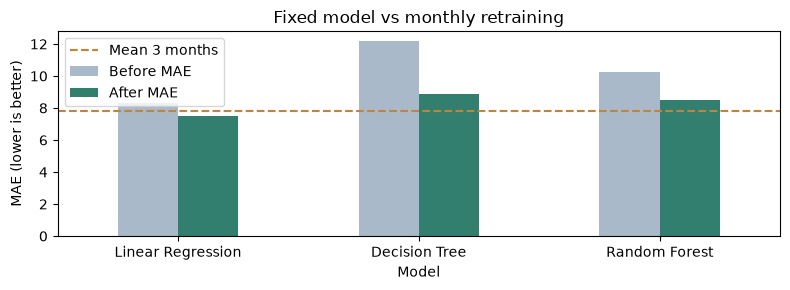

In [38]:
# ใช้ชื่อโมเดลเป็นชื่อกลุ่มบนแกนนอน
scores = test_scores.set_index("Model")

# วาดกราฟแท่งของทั้งสองวิธี
ax = scores[["Before MAE", "After MAE"]].plot.bar(
    figsize=(8, 3),
    rot=0,
    color=["#a9b9c9", "#327f70"]
)

# เพิ่มเส้นประแสดง MAE ของวิธีค่าเฉลี่ย 3 เดือน
ax.axhline(
    baseline_mae,
    color="#c78332",
    linestyle="--",
    label="Mean 3 months"
)

# ตั้งชื่อกราฟและแกนตั้ง
ax.set_title("Fixed model vs monthly retraining")
ax.set_ylabel("MAE (lower is better)")

# แสดงคำอธิบายสี จัดระยะ และแสดงกราฟ
ax.legend()
plt.tight_layout()
plt.show()

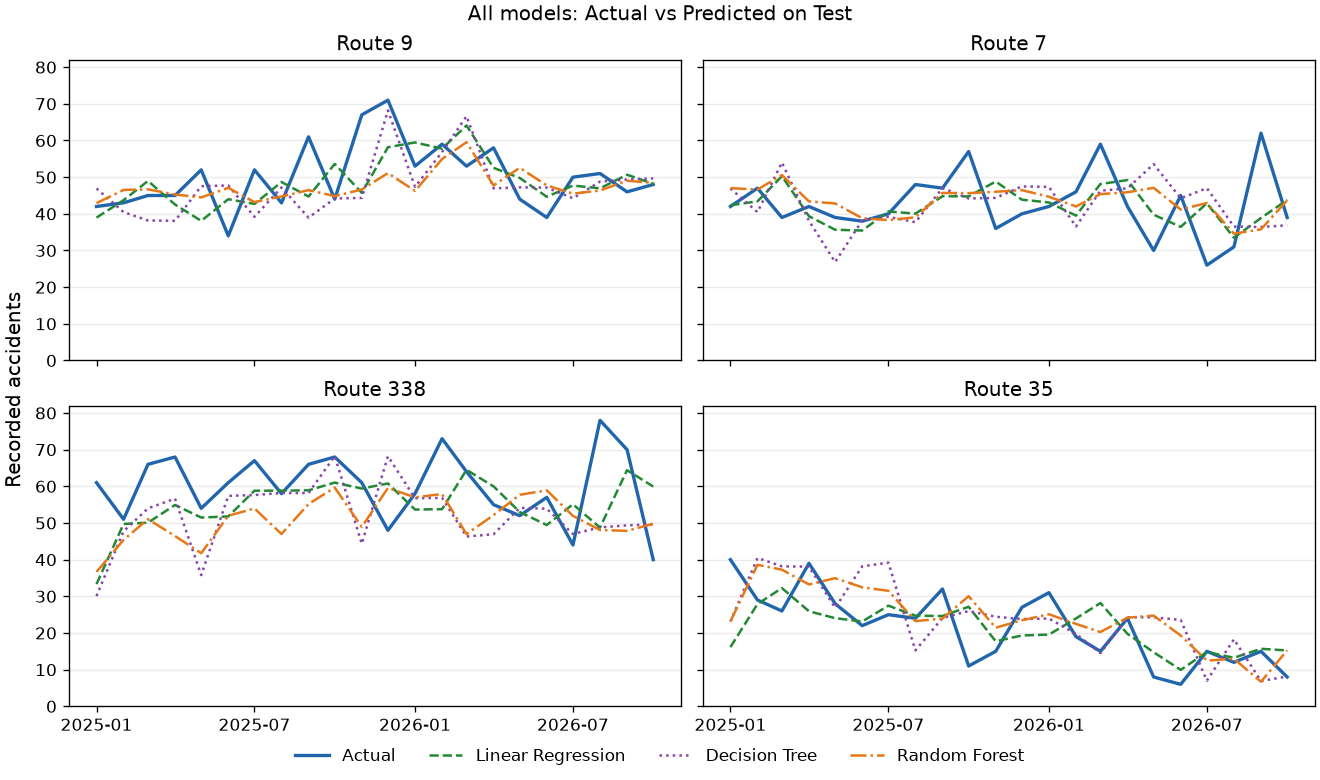

In [39]:
# เซลล์นี้วาดกราฟรวมค่าจริงเทียบค่าทำนายของทั้ง 3 โมเดล
from matplotlib import dates as mdates

# ใช้สีและรูปแบบเส้นเดียวกันในทุกรูป
styles = {
    "Linear Regression": ("#228833", "--"),
    "Decision Tree": ("#8844aa", ":"),
    "Random Forest": ("#e67817", "-."),
}

# หาเพดานแกนตั้งร่วมจากค่าสูงสุดของค่าจริงและค่าทำนาย
max_count = max(
    result[["actual", "prediction"]].max().max()
    for result in predictions_by_model.values()
)

def plot_test_predictions(model_names, title):
    # แต่ละรูปมี 4 ช่อง ช่องละหนึ่งสายทาง
    fig, axes = plt.subplots(
        2, 2, figsize=(11, 6.5), sharex=True, sharey=True, layout="constrained"
    )
    actual = predictions_by_model[best_name]

    for ax, route in zip(axes.flat, routes):
        # วาดค่าจริงของสายทางนี้
        actual_route = actual[actual["route_id"] == route]
        ax.plot(actual_route["month"].dt.to_timestamp(), actual_route["actual"],
                color="#2166ac", linewidth=2, label="Actual")

        # วาดเส้นทำนายของโมเดลที่ระบุ
        for name in model_names:
            result = predictions_by_model[name]
            route_result = result[result["route_id"] == route]
            color, line_style = styles[name]
            ax.plot(route_result["month"].dt.to_timestamp(), route_result["prediction"],
                    color=color, linestyle=line_style, label=name)

        ax.set_title("Route " + route.split(":")[-1])
        ax.grid(axis="y", alpha=0.25)

    # ใช้สเกลเดียวกันทุกรูป และแสดงป้ายเดือนทุก 6 เดือน
    axes[0, 0].set_ylim(0, max_count * 1.05)
    axes[1, 0].xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    axes[1, 0].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))

    # ใช้คำอธิบายเส้นร่วมกันทั้ง 4 ช่อง
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside lower center", ncols=4, frameon=False)
    fig.suptitle(title)
    fig.supylabel("Recorded accidents")
    plt.show()

# แสดงกราฟรวมของทั้ง 3 โมเดล
plot_test_predictions(list(styles), "All models: Actual vs Predicted on Test")

### Heatmap เปรียบเทียบ MAE รายสายทาง

แต่ละช่องแสดงจำนวนเหตุที่ทำนายคลาดเคลื่อนเฉลี่ยต่อเดือนในชุด Test **ตัวหนา** คือค่า MAE ต่ำที่สุดในสายทางนั้น สีเข้มขึ้นเมื่อความคลาดเคลื่อนสูงขึ้น

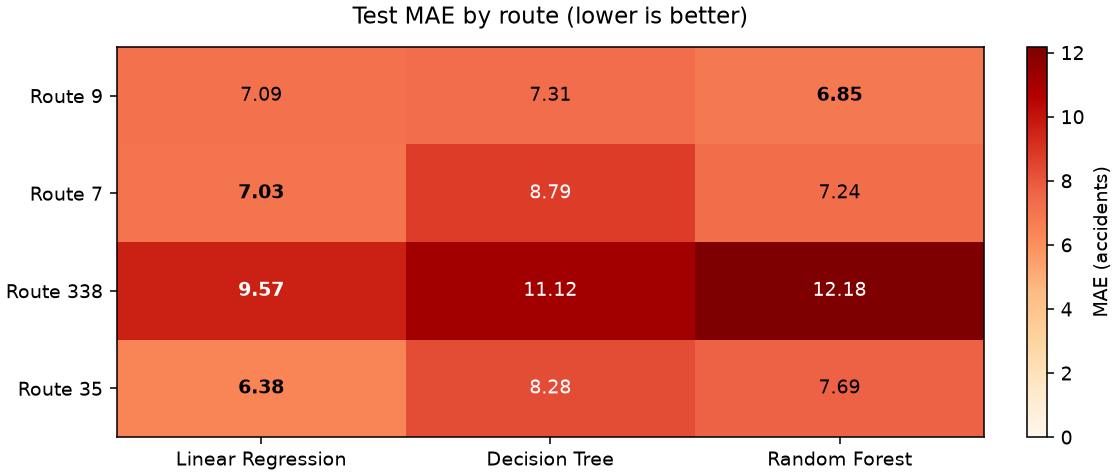

In [ ]:
# เซลล์นี้คำนวณ MAE รายสายทางและแสดงเป็น Heatmap
route_labels = ["Route " + route.split(":")[-1] for route in routes]
route_mae = pd.DataFrame(index=route_labels, columns=list(predictions_by_model), dtype=float)

# คำนวณความคลาดเคลื่อนของแต่ละโมเดลในแต่ละสายทาง
for name, result in predictions_by_model.items():
    for route, label in zip(routes, route_labels):
        rows = result[result["route_id"] == route]
        route_mae.loc[label, name] = mean_absolute_error(rows["actual"], rows["prediction"])

# ให้สีของแต่ละช่องขึ้นกับค่า MAE
fig, ax = plt.subplots(figsize=(8, 3.4), layout="constrained")
colors = ax.imshow(route_mae, cmap="OrRd", vmin=0, aspect="auto")
ax.set_xticks(range(len(route_mae.columns)), route_mae.columns)
ax.set_yticks(range(len(route_mae.index)), route_mae.index)
ax.set_title("Test MAE by route (lower is better)", pad=12)
fig.colorbar(colors, ax=ax, label="MAE (accidents)")

# ใส่ตัวเลขในแต่ละช่อง และเน้นค่าต่ำสุดของสายทางนั้น
for row_index, (_, values) in enumerate(route_mae.iterrows()):
    for column_index, value in enumerate(values):
        red, green, blue, _ = colors.cmap(colors.norm(value))
        brightness = 0.299 * red + 0.587 * green + 0.114 * blue
        ax.text(column_index, row_index, f"{value:.2f}", ha="center", va="center",
                color="black" if brightness > 0.5 else "white",
                fontweight="bold" if round(value, 2) == round(values.min(), 2) else "normal")

plt.show()

**อ่านผลจากกราฟโมเดล**

- บน Test วิธีฝึกใหม่ทุกเดือนให้ MAE ต่ำกว่าวิธีฝึกครั้งเดียวทั้ง 3 โมเดล
- บนสายทาง 9 ทั้ง 3 โมเดลทำนายต่ำกว่าค่าจริงในเดือนที่มีเหตุสูง เช่น พ.ย.–ธ.ค. 2568
- Heatmap แสดงว่า Random Forest มี MAE ต่ำที่สุดในสายทาง 9 ส่วน Linear Regression ต่ำที่สุดในสายทาง 7, 338 และ 35 เมื่อเทียบในกลุ่ม 3 โมเดล

### ลองพยากรณ์เดือนถัดไป
ฝึกชนิดโมเดลที่เลือกจาก Validation ด้วยประวัติทั้งหมดที่รู้แล้ว เพื่อทำนายต่อจากข้อมูลล่าสุด
นี่คือวิธีเดียวกับที่จำลองตอนประเมิน: ฝึกก่อนทำนายแต่ละเดือน และยังไม่มีค่าจริงของเดือนเป้าหมายให้ใช้

In [40]:
# เซลล์นี้เตรียมข้อมูลเดือนถัดไป พร้อม features ย้อนหลังของทั้ง 4 สายทาง

# หาเดือนถัดจากเดือนล่าสุดในข้อมูล
next_month = months.max() + 1

# สร้างแถวใหม่ของแต่ละสายทาง โดยยังไม่ทราบจำนวนเหตุจริง
new_rows = pd.DataFrame({
    "route_id": routes,
    "month": next_month,
    "count": np.nan
})

# รวมกับข้อมูลเดิม แล้วสร้าง features ย้อนหลัง
future = add_features(
    pd.concat([monthly, new_rows], ignore_index=True)
)

# เก็บเฉพาะเดือนที่จะทำนาย
future = future[future["month"] == next_month].copy()

In [41]:
# เซลล์นี้ทำนายจำนวนอุบัติเหตุเดือนถัดไปของทั้ง 4 สายทาง

# รวมข้อมูลย้อนหลังที่ทราบคำตอบแล้วทั้งหมด
all_known = pd.concat(
    [train_clean, validation, test],
    ignore_index=True
)

# สร้างสำเนาโมเดลชนิดที่เลือกจาก Validation แล้วฝึกใหม่
final_model = clone(best_model)
final_model.fit(all_known[features], all_known["count"])

# ทำนายจำนวนเหตุของเดือนถัดไป
future["forecast"] = final_model.predict(future[features])

# ปรับค่าทำนายที่ติดลบให้เป็น 0
future["forecast"] = future["forecast"].clip(lower=0)

# แสดงสายทาง เดือน และจำนวนเหตุคาดการณ์ โดยปัดทศนิยม 1 ตำแหน่ง
future[["route_id", "month", "forecast"]].round({"forecast": 1})

,route_id,month,forecast
282,กรมทางหลวง:338,2026-11,52.5
283,กรมทางหลวง:35,2026-11,12.5
281,กรมทางหลวง:7,2026-11,43.7
280,กรมทางหลวง:9,2026-11,47.4


### สรุปผลโมเดล

ตารางนี้เปรียบเทียบโมเดลแบบฝึกใหม่ทุกเดือนกับ Baseline บน Test ช่วง ม.ค. 2568–ต.ค. 2569 ค่า MAE คือจำนวนเหตุที่ทำนายคลาดเคลื่อนเฉลี่ยต่อสายทางต่อเดือน ยิ่งต่ำยิ่งดี

| วิธีพยากรณ์ | Test MAE (เหตุ) |
|---|---:|
| Linear Regression | **7.52** |
| Baseline ค่าเฉลี่ยย้อนหลัง 3 เดือน | 7.83 |
| Random Forest | 8.49 |
| Decision Tree | 8.88 |

**Random Forest ถูกเลือกจาก Validation** แต่เมื่อประเมินบน Test ได้ MAE **8.49 เหตุ** ซึ่งสูงกว่า Baseline ที่ **7.83 เหตุ** ส่วน **Linear Regression** ได้ MAE **7.52 เหตุ** หรือต่ำกว่า Baseline ประมาณ **4%** บน Test ชุดนี้

ผลนี้เป็นการประเมินย้อนหลังบนข้อมูลที่เคยสำรวจแล้ว ส่วนข้อมูลปี 2569 ไม่มีรหัสเหตุ จึงอาจตรวจรายงานซ้ำได้ไม่ครบ